# 018 — Adam vs. SGD

## Objetivo e protocolo

Mantém a arquitetura 64 → 32, ReLU, pré-processamento normalizado, CrossEntropyLoss com pesos 1/frequência e `batch_size=128` do 015. Compara Adam nas taxas 0.0001 e 0.001 e SGD com `momentum=0.9` nas taxas 0.001, 0.01 e 0.05, até 100 épocas. A rede, o otimizador, o gerador de minibatches e as sementes são reiniciados para cada configuração.

Reutiliza exatamente as divisões estratificadas 80/20 e interna de 15% do 015 (`random_state=42`). A taxa e a época de cada otimizador são escolhidas pela Macro F1 interna. Os dois finalistas são reajustados em redes novas nos 80% e avaliados nos 20% fixos. A exportação escolhe sempre o finalista SGD pela validação interna, mesmo que Adam vença a avaliação fixa, e treina uma nova rede nas 10.962 linhas rotuladas.

Referência 015: Macro F1 fixa **0.4224**, Kaggle **0.44**.

,optimizer,learning_rate,momentum,best_epoch,internal_macro_f1,training_seconds
0,Adam,0.0001,nan,93,0.4792,22.6
1,Adam,0.001,nan,12,0.4742,23.7
2,SGD,0.001,0.900000,93,0.4784,14.2
3,SGD,0.01,0.900000,48,0.4612,14.6
4,SGD,0.05,0.900000,62,0.4524,15.6


,otimizador,macro_f1,accuracy,diferença vs 015
0,Adam,0.4224,0.4191,+0.0000
1,SGD,0.4365,0.4364,+0.0141


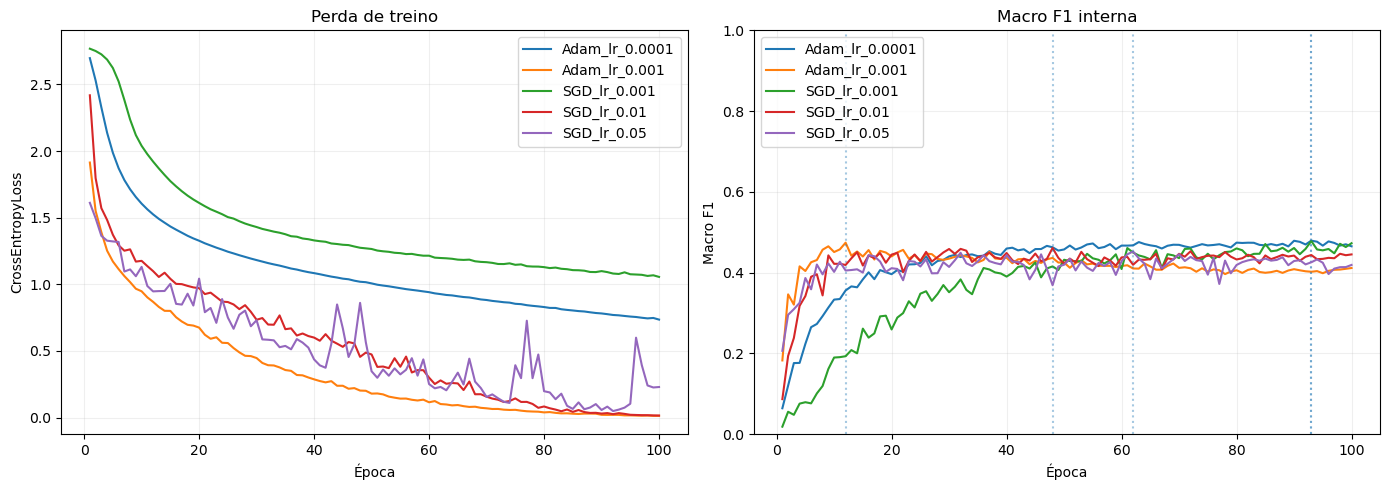

Métricas por classe — Adam


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.6575,0.5854,41
1,1,18–19 anos,0.4731,0.6471,34
2,2,20–24 anos,0.4789,0.4250,80
3,3,25–29 anos,0.3815,0.4400,75
4,4,30–34 anos,0.2812,0.3000,90
5,5,35–39 anos,0.3383,0.3488,129
6,6,40–44 anos,0.3463,0.3372,172
7,7,45–49 anos,0.3397,0.3064,173
8,8,50–54 anos,0.5989,0.6022,181
9,9,55–59 anos,0.5753,0.5271,203


Métricas por classe — SGD


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.6667,0.5854,41
1,1,18–19 anos,0.5143,0.7941,34
2,2,20–24 anos,0.4132,0.3125,80
3,3,25–29 anos,0.4123,0.6267,75
4,4,30–34 anos,0.1757,0.1444,90
5,5,35–39 anos,0.3665,0.3566,129
6,6,40–44 anos,0.3178,0.2965,172
7,7,45–49 anos,0.3700,0.3988,173
8,8,50–54 anos,0.5801,0.5304,181
9,9,55–59 anos,0.6025,0.5862,203


CSV exportado (sempre SGD): submissions/submission_018_mlp_sgd.csv
Exploratória face à referência 015: False
Comparações de previsões por RowId, incluindo todos os CSVs disponíveis:


,csv_a,csv_b,previsoes_diferentes,duplicado
0,submission_016_xgboost_mlp015.csv,submission_001_regressao_logistica.csv,1345,False
1,submission_016_xgboost_mlp015.csv,submission_002_regressao_logistica_regularizad...,1129,False
2,submission_016_xgboost_mlp015.csv,submission_004_arvore_decisao.csv,2106,False
3,submission_016_xgboost_mlp015.csv,submission_007_xgboost.csv,458,False
4,submission_016_xgboost_mlp015.csv,submission_010_mlp_pytorch.csv,1261,False
5,submission_016_xgboost_mlp015.csv,submission_012_mlp_perda_ponderada.csv,1307,False
6,submission_016_xgboost_mlp015.csv,submission_014_xgboost_mlp.csv,253,False
7,submission_016_xgboost_mlp015.csv,submission_015_mlp_learning_rate.csv,1101,False
8,submission_016_xgboost_mlp015.csv,submission_017_mlp_ponderacao_suave.csv,1092,False
9,submission_016_xgboost_mlp015.csv,submission_018_mlp_sgd.csv,1428,False


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repo_root = next(p for p in [Path.cwd(), *Path.cwd().resolve().parents]
                 if (p / "src" / "experiments_016_018.py").is_file())
sys.path.insert(0, str(repo_root))
from src.experiments_016_018 import run_018, compare_submissions

output = run_018()
result, histories, search_table = output["result"], output["histories"], output["search_table"]
display(search_table.drop(columns="history_key").style.format({
    "learning_rate": "{:.4g}", "internal_macro_f1": "{:.4f}", "training_seconds": "{:.1f}"
}))
finalists = pd.DataFrame([
    {"otimizador": "Adam", **result["adam_metrics"]},
    {"otimizador": "SGD", **result["sgd_metrics"]},
])[["otimizador", "macro_f1", "accuracy"]]
finalists["diferença vs 015"] = finalists.macro_f1 - 0.4224
display(finalists.style.format({"macro_f1": "{:.4f}", "accuracy": "{:.4f}", "diferença vs 015": "{:+.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, history in histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], label=label)
    axes[1].plot(history["epoch"], history["validation_macro_f1"], label=label)
    selected = next(row for row in result["search_rows"] if row["history_key"] == label)
    axes[1].axvline(selected["best_epoch"], linestyle=":", alpha=.4)
axes[0].set(title="Perda de treino", xlabel="Época", ylabel="CrossEntropyLoss")
axes[1].set(title="Macro F1 interna", xlabel="Época", ylabel="Macro F1", ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=.2)
    axis.legend()
plt.tight_layout()
plt.show()

for name in ["Adam", "SGD"]:
    table = pd.DataFrame(result[f"{name.lower()}_metrics"]["per_class"])
    print(f"Métricas por classe — {name}")
    display(table.style.format({"F1": "{:.4f}", "recall": "{:.4f}"}).apply(
        lambda row: ["font-weight: bold" if row.classe in [1, 6, 13] else "" for _ in row], axis=1
    ))
print("CSV exportado (sempre SGD):", result["submission"])
print("Exploratória face à referência 015:", result["exploratory"])
print("Comparações de previsões por RowId, incluindo todos os CSVs disponíveis:")
display(compare_submissions())

## Conclusão

- Data: 11/11; pontuação Kaggle: 0.44, abaixo do 017 (0.46) e do melhor resultado atual, o ensemble 016 (0.48). O 017 permanece o melhor MLP no Kaggle.
- Macro F1 fixa: 0.4365, mais 0.0014 que o 017 (0.4351); a validação fixa já consultada é apenas comparação de desenvolvimento.
- A seleção interna favoreceu Adam por margem pequena, enquanto o SGD teve melhor resultado na validação fixa.
- Melhorias: comparar ponderação suave mantendo a configuração SGD selecionada.
